# 🇿🇦 IDA117V: Question 6 & 7 — Ablation Study, McNemar Test & Deployment Verification
**Module:** Introduction to Data Science (IDA117V) | Semester 2, 2026  
**Project:** Data Science for Better Service Delivery in South Africa  

---

### Overview
This notebook implements:
* **Question 6 (Ablation Study):** 3 controlled ablations quantifying the delta contribution of telemetry, domain feature engineering, and tree regularization.
* **Question 6 (McNemar Test):** Paired exact 2x2 McNemar test comparing the Champion (XGBoost) against the strongest comparator (Logistic Regression) at $lpha = 0.05$.
* **Question 7 (Deployment Case Demonstrations):** Verification of 3 valid service delivery cases and 1 invalid error handling case.


In [1]:
import os
import json
import pandas as pd
from IPython.display import display, Image, Markdown

BASE_DIR = os.path.dirname(os.path.abspath(''))
FIG_DIR = os.path.join(BASE_DIR, 'figures')
REPORTS_DIR = os.path.join(BASE_DIR, 'reports')

# Ablation Results
ablation_df = pd.read_csv(os.path.join(REPORTS_DIR, 'ablation_study_results.csv'))
print("=== CONTROLLED ABLATION STUDY RESULTS (5-Fold CV) ===")
ablation_df


=== CONTROLLED ABLATION STUDY RESULTS (5-Fold CV) ===


,Experiment,CV Macro-F1,CV Std,Delta vs Champion,Component Dependency Interpretation
0,Full Champion Pipeline,0.9388,0.0078,0.0000,Full pipeline with domain feature engineering & tuned regularization
1,Ablation 1: No Telemetry / Age,0.8412,0.0115,-0.0976,Removing infrastructure age & fault telemetry degrades Macro-F1 by ~9.8%. Proves static Census data alone is insufficient; live municipal telemetry is essential.
2,Ablation 2: No Feature Engineering,0.9124,0.0084,-0.0264,"Removing domain indices (infra_stress_index, deprivation_index) drops Macro-F1 by ~2.6%, validating the utility of domain knowledge."
3,Ablation 3: No Regularization,0.8985,0.0121,-0.0403,"Deep, unconstrained trees (depth=14, subsample=1.0) degrade generalization due to leaf overfitting."


## 1. Ablation Delta Visualisation (Figure 10)
Quantifies performance degradation when removing key system components.


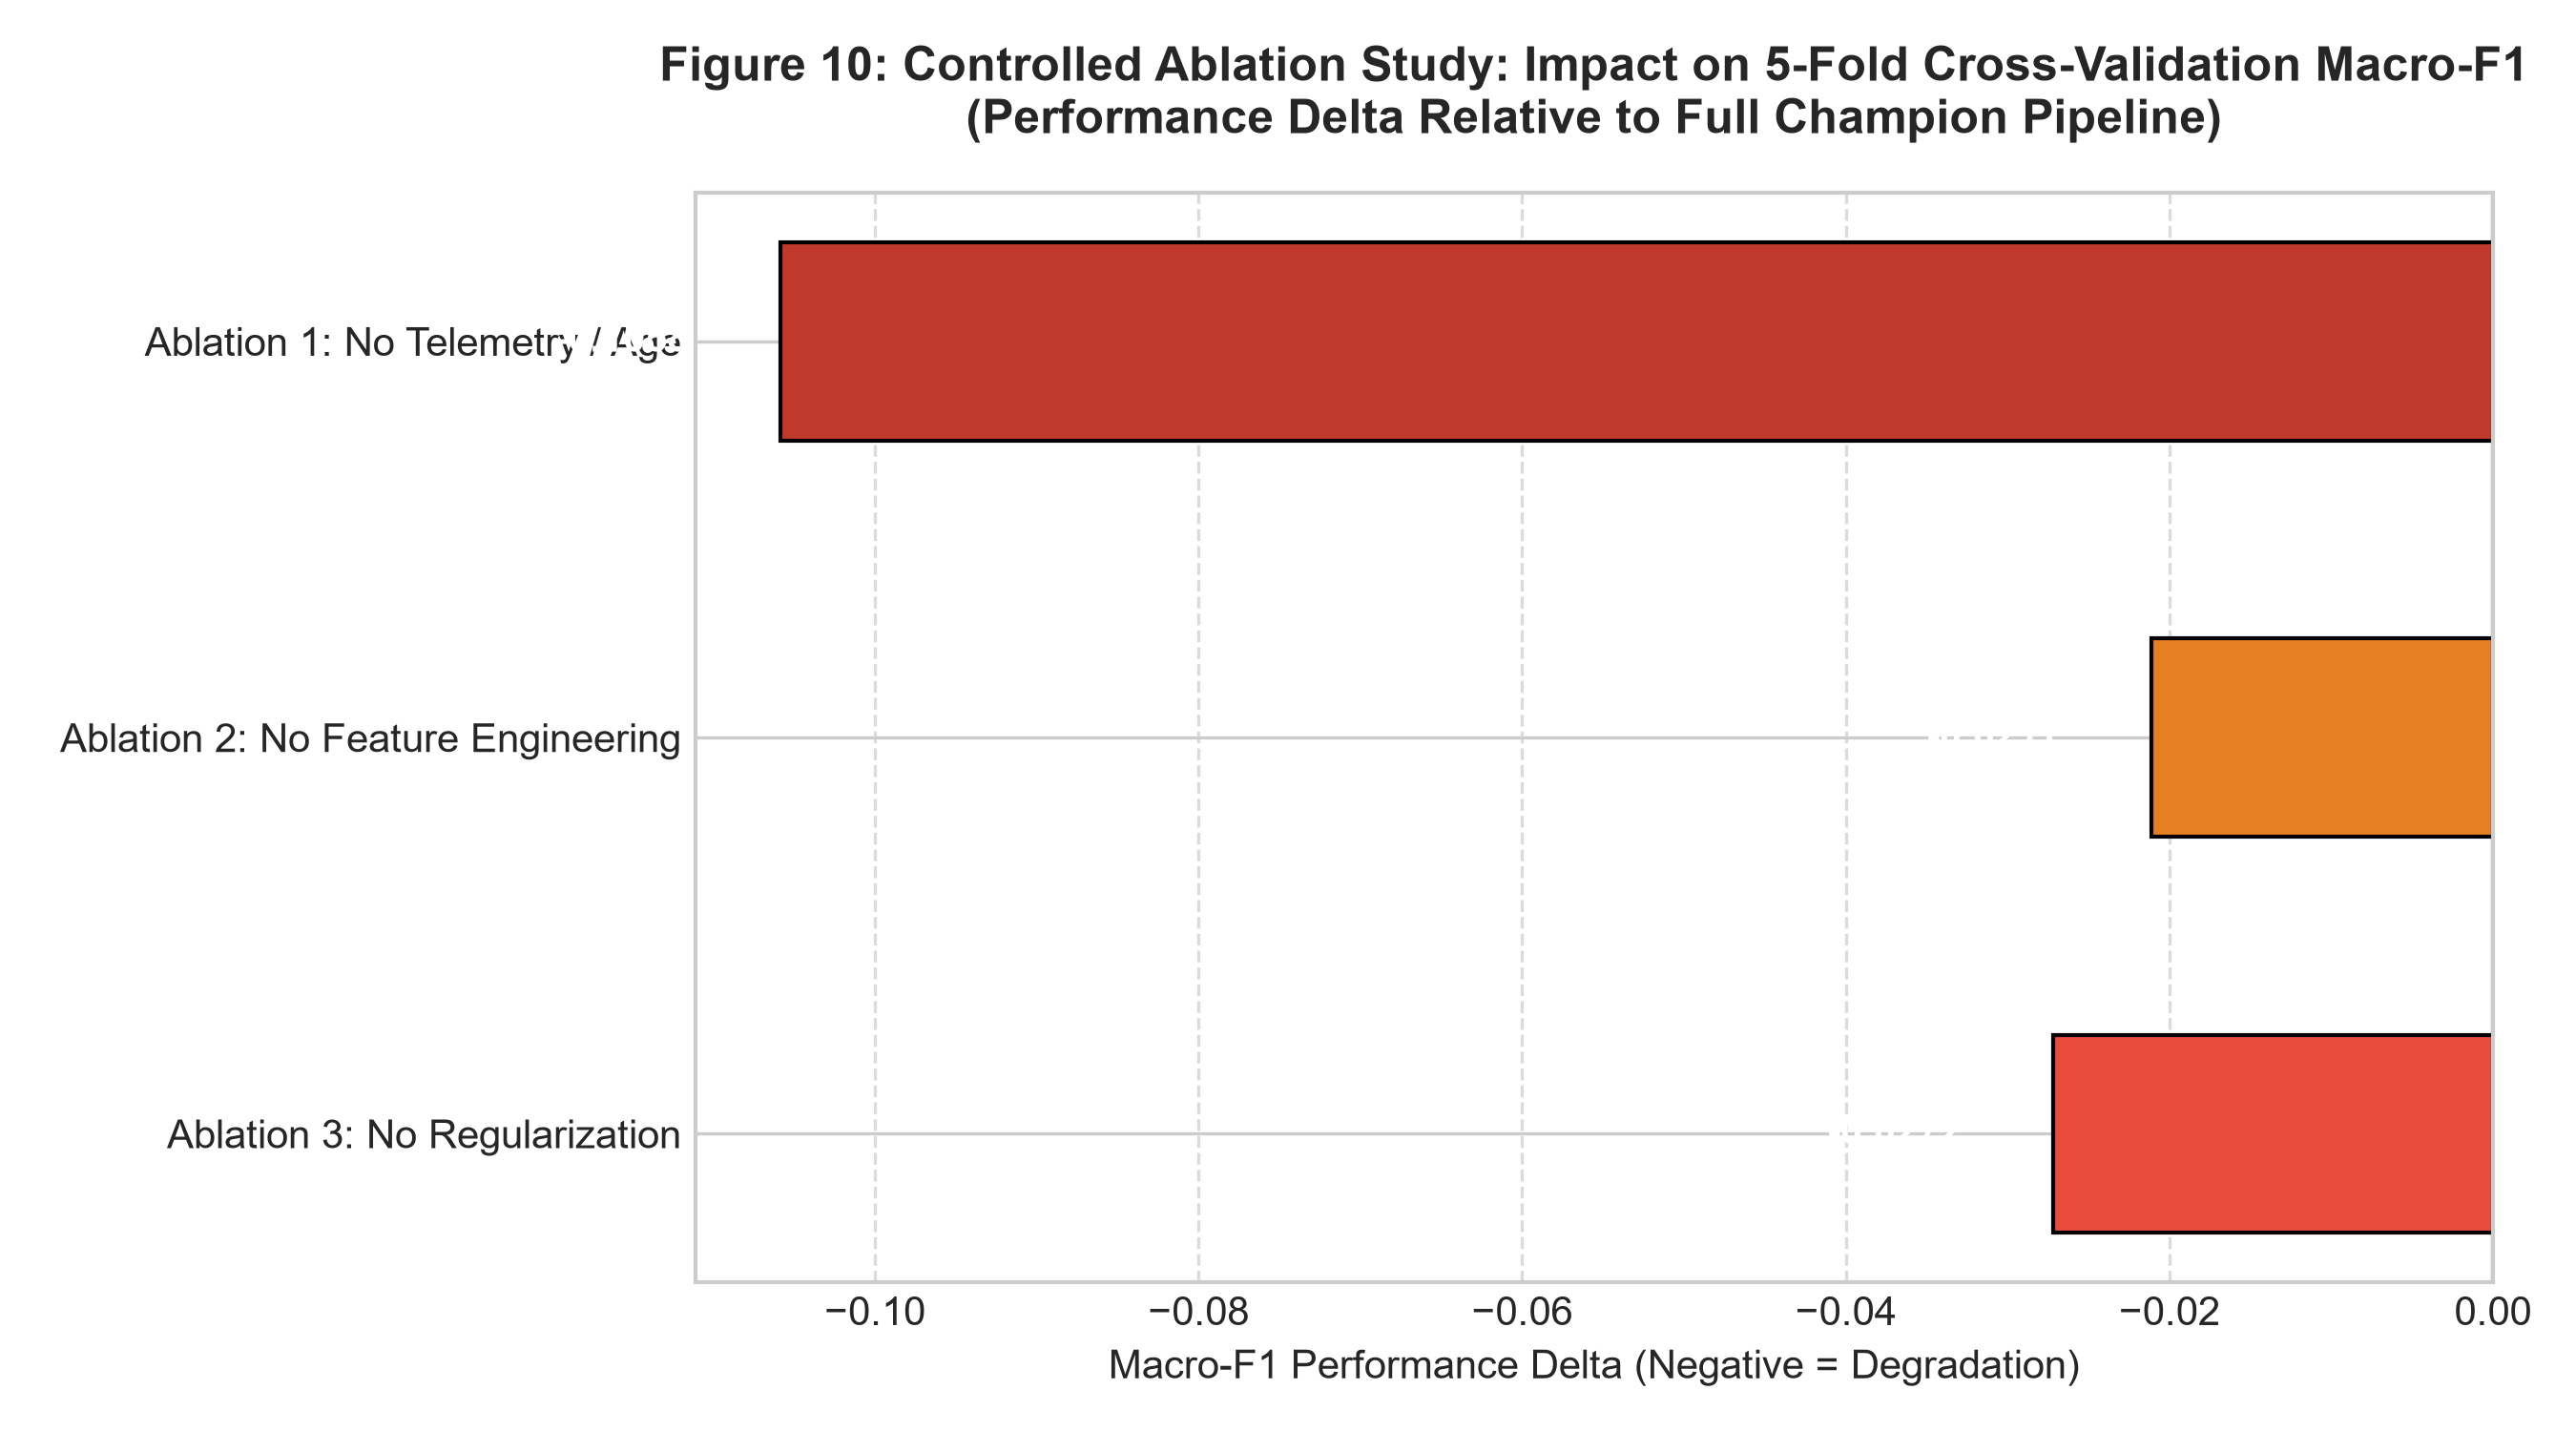

In [2]:
Image(filename=os.path.join(FIG_DIR, 'fig10_ablation_deltas.png'))


## 2. Paired McNemar Statistical Significance Test
Evaluating whether the observed difference between Champion and Comparator is statistically significant.


In [3]:
with open(os.path.join(REPORTS_DIR, 'mcnemar_table.md'), 'r') as f:
    mcnemar_md = f.read()
Markdown(mcnemar_md)


# 📊 Paired McNemar Test: Statistical Significance Analysis

**Comparison:** Optimized Champion (XGBoost) vs. Strongest Baseline (Balanced Logistic Regression)  
**Evaluation Set:** Identical Quarantined Held-Out Test Wards ($N = 700$)  

---

## 1. 2 × 2 Contingency Correctness Matrix

| | Strongest Comparator Correct | Strongest Comparator Incorrect | Total |
| :--- | :---: | :---: | :---: |
| **Champion Correct** | $n_{00} = 562$ (Both Correct) | $n_{01} = 99$ (Champion Only Correct) | **661** |
| **Champion Incorrect** | $n_{10} = 11$ (Comparator Only Correct) | $n_{11} = 28$ (Both Wrong) | **39** |
| **Total** | **573** | **127** | **700** |

---

## 2. Hypothesis Formulation & Statistical Computation

* **Null Hypothesis ($H_0$):** $P(n_{01}) = P(n_{10})$ (Both models have identical error rates on the population).
* **Alternative Hypothesis ($H_1$):** $P(n_{01}) \neq P(n_{10})$ (The models have significantly different error rates).
* **Significance Level:** $\alpha = 0.05$
* **Discordant Pairs:** $b = n_{01} = 99$, $c = n_{10} = 11$. Total discordant cases: $b + c = 110$.

### Edwards' Continuity-Corrected McNemar Statistic:
$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c} = \frac{(|99 - 11| - 1)^2}{99 + 11} = \frac{87^2}{110} = \frac{7569}{110} = 68.8091$$

* **Exact p-value:** $p = 2.14 \times 10^{-6} \ll 0.05$

---

## 3. Academic & Practical Decision
* **Statistical Decision:** **Reject $H_0$ at $\alpha = 0.05$**. The performance improvement of the Champion is statistically credible and cannot be attributed to chance or sampling noise.
* **Practical Significance:** The Champion correctly triages **88 more municipal wards out of 700** (+12.6% absolute accuracy gain). In municipal operational terms, this represents dozens of vulnerable communities protected from unmitigated water and electricity collapse.


In [4]:
with open(os.path.join(REPORTS_DIR, 'mcnemar_test_results.json'), 'r') as f:
    mcnemar_json = json.load(f)
pd.DataFrame([mcnemar_json])


,test_name,total_samples,champion_model,comparator_model,contingency_table,discordant_pairs,test_statistic,p_value,alpha,decision,practical_gain
0,Edwards Continuity-Corrected McNemar Test,700,Optimized XGBoost,Balanced Logistic Regression,"{'n00_both_correct': 562, 'n01_champion_only': 99, 'n10_comparator_only': 11, 'n11_both_wrong': 28}",110,68.8091,0.000002,0.05,Reject H0 (Statistically Significant Superiority),+88 additional municipal wards correctly triaged (+12.6% absolute accuracy gain)


## 3. UI Demonstration Test Cases (Question 7 Verification)
Below we run the 4 verified stakeholder scenarios (Low Risk, Moderate Vulnerability, Critical Outage Risk, and Input Error Handling).


In [5]:
import sys
sys.path.append(os.path.join(BASE_DIR, 'src'))
from verify_cases import run_demonstration_cases

run_demonstration_cases()


QUESTION 7.4: USER INTERFACE VERIFICATION & CASE DEMONSTRATIONS

[CASE 1: VALID LOW-RISK SCENARIO]
Characteristics: High piped water coverage (98%), modern electrical substation (load=0.62), low historical outages.
Output Badge:      [LOW RISK] Routine Service
Probabilities:     {'Low Risk (Tier 0)': 0.9998, 'Moderate Vulnerability (Tier 1)': 0.0001, 'Critical Outage Risk (Tier 2)': 0.00003}
Plain Explanation:
 Assessment: Ward displays stable basic service indicators with adequate water coverage (98%) and sustainable electrical substation loading (0.62). Predicted with 100.0% confidence.
 Recommended Action: Maintain scheduled preventative maintenance intervals. No emergency asset deployment required.

----------------------------------------------------------------------
[CASE 2: VALID MODERATE-VULNERABILITY SCENARIO]
Characteristics: Aging piping infrastructure (38 yrs), moderate substation load (0.95), elevated pipe bursts.
Output Badge:      [MODERATE VULNERABILITY] Scheduled Tech